<a href="https://colab.research.google.com/github/andreacangiani/NSPDE-ANA2024/blob/main/Python/CP5_worked.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Finite Element Method in 1D

1. Linear ($k=1$) Finite Element Method solver for the 1D Poisson problem:

$-u''=f \quad \in \Omega=(a,b)^2$

$u(a)=0=u(b)$

Import usual modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
from scipy.sparse.linalg import eigsh

FEM system assembly with trapezoidal rule for rhs

In [2]:
def FEM1_1D_TRAP(omega,N,rhs):
  # 1D FEM with k=1 system matrix and rhs for
  # diffusion problem with homogeneous Dirichlet bc
  # trapezoidal rule uniform grid

  # grid is defined here as uniform
  h = (omega[1]-omega[0]) / N
  x = np.linspace(omega[0],omega[1],N+1)

  # initialise system
  A = sp.lil_matrix((N+1,N+1))
  F = np.zeros(N+1)

  # Assembly loop
  for i in range(N):
    # local contributions
    A_ele = np.matrix([[1/h, -1/h],[-1/h, 1/h]])
    F_ele = 0.5 * h * rhs(x[i:i+2])
    # Assembly local-to-global
    A[i:i+2,i:i+2] += A_ele
    F[i:i+2] += F_ele

  # Apply boundary conditions
  A[0,0] = 1/h; A[0,1] = 0; F[0] = 0
  A[N,N] = 1/h; A[N,N-1] = 0; F[N] = 0

  # return system matrix and rhs vector
  return A, F

Define FEM problem and solve

8.225076221068939e-05


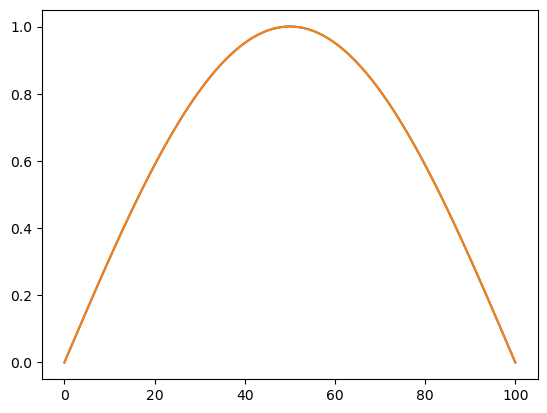

In [3]:
# problem's data
omega = [0,np.pi]
rhs = lambda x: np.sin(x)
exact = lambda x: np.sin(x)

# number of subdivisions
N=100;

# call function computing FEM system
A, F = FEM1_1D_TRAP(omega,N,rhs)

# solve
A = A.tocsr()
Uh = sp.linalg.spsolve(A,F)

# Evaluate exact solution at grid nodes
x = np.linspace(omega[0],omega[1],N+1)
U = exact(x)

# Plot solutions
plt.plot(Uh)
plt.plot(U)

# compute discrete max norm error
print(max(abs(U-Uh)))

2. Repeat exercise but for the non-homogeneous Dirichlet conditions, so:

$-u''=f \quad \in \Omega=(a,b)^2$

$u(a)=g(a)$ and $u(b)=g(b)$

for $g$ a given function.

Also:
- allow for nonuniform grid
- use reference element to assemble
- to compute the rhs, use arbitrary order Gauss integration

In [4]:
# Gauss quadrature formula on [0,1]
def quadrature(n_quadrature_points):

  # exploit numpy Gauss quadrature. This is defined in [-1,1]
  q, w = np.polynomial.legendre.leggauss(n_quadrature_points)

  return (q+1)/2, w/2

Function defining the mesh

In [5]:
def mesh(omega,N):
  return np.linspace(omega[0],omega[1],N+1)

Define reference element transformation of coordinates

In [6]:
# Transformation of coordinates functions:
# reference element -> current element
# [0,1] -> [q[i], q[i+1]]

def mapping(q, i):
    # check index is within range
    assert i < len(q)-1
    assert i >= 0
    return lambda x: q[i] + (q[i+1]-q[i]) * x


def mapping_J(q,i):
    assert i < len(q)-1
    assert i >= 0
    return q[i+1]-q[i]


# Linear lagrange basis on reference element
def basis1(i):
    assert i < 2
    assert i >= 0
    if i == 0:
      phi = lambda x: 1-x
    else:
      phi = lambda x: x
    return phi


# Linear lagrange basis derivatives on reference element
def basis1_derivative(i):
    assert i < 2
    assert i >= 0
    if i == 0:
      dphi = lambda x: -np.ones(len(x))
    else:
      dphi = lambda x: np.ones(len(x))
    return dphi



FEM system assembly with Gauss integration



In [7]:
def FEM1_1D_GAUSS(omega,N,n_qpoints,rhs):
  # 1D FEM with k=1 system matrix and rhs
  # not accounting for boundary conditions

  # grid
  vertices = mesh(omega,N)

  # quadrature formula on reference element
  q, w = quadrature(n_qpoints)

  # Evaluation of the two local linear Lagrange basis
  phi = np.array([basis1(i)(q) for i in range(2)]).T
  dphi = np.array([basis1_derivative(i)(q) for i in range(2)]).T

  # initialise system
  A = sp.lil_matrix((N+1, N+1))
  F = np.zeros(N+1)

  # Assembly loop
  for i in range(N):
    JxW = mapping_J(vertices,i) * w
    A_ele = np.einsum('qi,qj,q',dphi,dphi,JxW)/ mapping_J(vertices,i)**2
    F_ele = np.einsum('qi,q,q',phi,rhs(mapping(vertices,i)(q)),JxW)

    A[i:i+2,i:i+2] += A_ele
    F[i:i+2] += F_ele


  # return system matrix and rhs vector
  return A, F

Function implementing the boundary (nonhomogeneous) Dirichlet conditions. (Similar to FD code, but boundary condition given by sunction $g$!)

In [8]:
def apply_boundary_conditions(omega,N, A, F, g):
    A[0,0] = 1; A[0,1] = 0; F[0] = g(omega[0])
    A[N,N] = 1; A[N,N-1] = 0; F[N] = g(omega[1])



Define FEM problem and solve

4.1126903210453314e-05


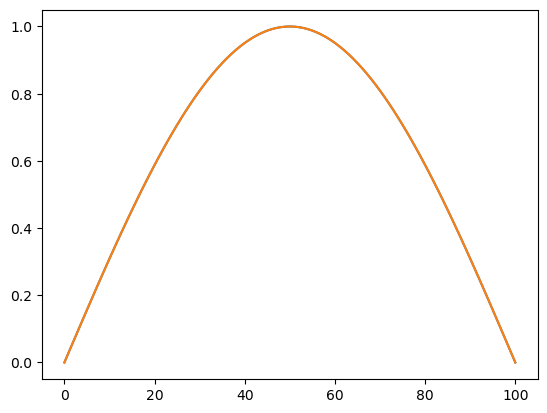

In [9]:
# problem's data
omega = [0,np.pi]
rhs = lambda x: np.sin(x)
exact = lambda x: np.sin(x)

# number of subdivisions
N=100;

n_qpoints = 1

# call function computing FEM system
A, F = FEM1_1D_GAUSS(omega,N,n_qpoints,rhs)
apply_boundary_conditions(omega,N, A, F, exact)

# solve
A = A.tocsr()
Uh = sp.linalg.spsolve(A,F)

# Evaluate exact solution at grid nodes
x = np.linspace(omega[0],omega[1],N+1)
U = exact(x)

# Plot solutions
plt.plot(Uh)
plt.plot(U)


# compute discrete max norm error
print(max(abs(U-Uh)))


Next we run few experiment to confirm the theoretical convergence and growth of the condition number.

In [13]:
noexp=8
Error=np.zeros(noexp)
NN=np.zeros(noexp)
Cond = np.zeros(8)

for i in range(noexp):
    N=2**(i+1)
    h=(omega[1]-omega[0])/N
    x=np.linspace(omega[0],omega[1],N+1)
    rhs = lambda x: np.sin(x)
    exact = lambda x: np.sin(x)
    A, F = FEM1_1D_GAUSS(omega,N,n_qpoints,rhs)
    apply_boundary_conditions(omega,N, A, F, exact)
    
    A = A.tocsr()
    Uh = sp.linalg.spsolve(A,F)
    U = exact(x)
    NN[i]=N

    Error[i]=max(abs(U-Uh))
    Cond[i] = np.linalg.cond(A.todense(),p=2)






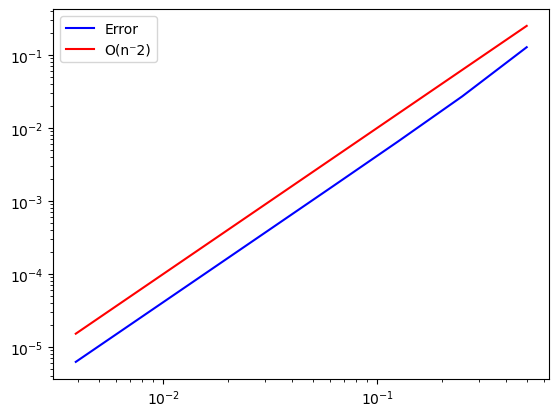

In [14]:
import matplotlib.pyplot as plt

plt.loglog(1/NN, Error, color='blue', label='Error')
plt.loglog(1/NN, 1/(NN**2), color='red', label='O(n⁻2)')

plt.legend()
plt.show()

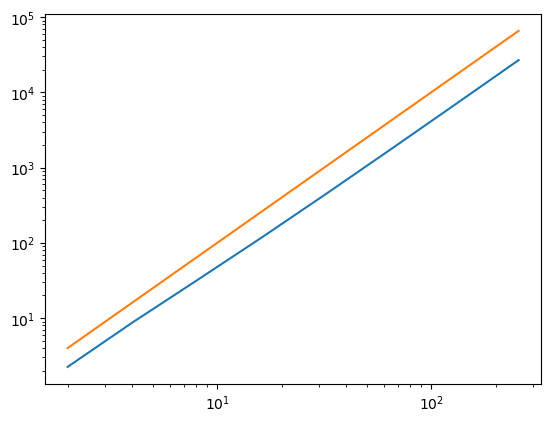

In [15]:
# Plot error
plt.loglog(NN,Cond)
plt.loglog(NN,NN**(2))

**Exercise 1** Write a function computing $H^1$-norm error

In [16]:
def sol(x):
    return np.sin(x)

def sol_derivative(x):
    return np.pi*np.cos(x)

def sol_second_derivative(x):
    return -np.pi**2*np.sin(np.pi*x)

def FEM1_H1(omega, N, n_qpoints, Uh, sol, sol_derivative):

    vertices = mesh(omega, N)
    q, w = quadrature(n_qpoints)

    phi = np.array([basis1(i)(q) for i in range(2)]).T
    dphi = np.array([basis1_derivative(i)(q) for i in range(2)]).T

    error = 0.0

    for i in range(N):

        J = mapping_J(vertices, i)
        x = mapping(vertices, i)(q)
        JxW = J * w

        # Numerical solution and its derivative
        Uh_ele = phi @ Uh[i:i+2]
        dUh_ele = (dphi @ Uh[i:i+2]) /J

        # Exact solution and its derivative
        u_exact = sol(x)
        du_exact = sol_derivative(x)

        # H1 error
        error += np.sum((u_exact - Uh_ele)**2 * JxW)
        error += np.sum((du_exact - dUh_ele)**2 * JxW)

    return np.sqrt(error)

and test convergence this time for $\| u - u_h \|_{H^1(a,b)}$.

In [ ]:
A= FEM1_H1(omega, N, n_qpoints, Uh, sol, sol_derivative)
print(A)

**Exercise 2**: Try same exercise, this time with nonuniform grid

**Exercise 3**: Write code solving general reaction-advection-diffusion problems